In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

# 3 data qubits, 2 ancillas, 2 classical bits
qc = QuantumCircuit(5, 2)

# Prepare logical |1> and encode it as |111>
qc.x(0)
qc.cx(0, 1)
qc.cx(0, 2)

# Inject a bit-flip error on data qubit 1
qc.x(1)

# First parity check: q0 XOR q1
qc.cx(0, 3)
qc.cx(1, 3)

# Second parity check: q0 XOR q2
qc.cx(0, 4)
qc.cx(2, 4)

# Measure the ancillas
qc.measure(3, 0)
qc.measure(4, 1)

print(qc.draw())

simulator = AerSimulator()
compiled = transpile(qc, simulator)

result = simulator.run(
    compiled, shots=1000
).result()

print("Syndrome:", result.get_counts())

     ┌───┐                                         
q_0: ┤ X ├──■────■─────────■─────────■─────────────
     └───┘┌─┴─┐  │  ┌───┐  │         │             
q_1: ─────┤ X ├──┼──┤ X ├──┼────■────┼─────────────
          └───┘┌─┴─┐└───┘  │    │    │             
q_2: ──────────┤ X ├───────┼────┼────┼────■────────
               └───┘     ┌─┴─┐┌─┴─┐  │    │  ┌─┐   
q_3: ────────────────────┤ X ├┤ X ├──┼────┼──┤M├───
                         └───┘└───┘┌─┴─┐┌─┴─┐└╥┘┌─┐
q_4: ──────────────────────────────┤ X ├┤ X ├─╫─┤M├
                                   └───┘└───┘ ║ └╥┘
c: 2/═════════════════════════════════════════╩══╩═
                                              0  1 
Syndrome: {'01': 1000}


In [16]:
# Number of data qubits
n_data = 49

# X-type stabilizer supports
x_checks = [
    [0,1],[1,2,8,9],[2,3],
    [3,4,10,11],[4,5],[5,6,12,13],
    [7,8,14,15],[9,10,16,17],[11,12,18,19],
    [15,16,22,23],[17,18,24,25],[19,20,26,27],
    [21,22,28,29],[23,24,30,31],[25,26,32,33],
    [29,30,36,37],[31,32,38,39],[33,34,40,41],
    [35,36,42,43],[37,38,44,45],[39,40,46,47],
    [43,44],[45,46],[47,48]
]

# Z-type stabilizer supports
z_checks = [
    [0, 1,7,8],[2,3,9,10],[4,5,11,12],
    [6,13],[7,14],[8,9,15,16],
    [10,11,17,18],[12,13,19,20],[14,15,21,22],
    [16,17,23,24],[18,19,25,26],[20,27],
    [21,28],[22,23,29,30],[24,25,31,32],
    [26,27,33,34],[28,29,35,36],[30,31,37,38],
    [32,33,39,40],[34,41],[35,42],
    [36,37,43,44],[38,39,45,46],[40,41,47,48]
]

print("Number of data qubits:", n_data)
print("Number of X checks:", len(x_checks))
print("Number of Z checks:", len(z_checks))

print("\nX-type stabilizers:")
for i, support in enumerate(x_checks):
    print(f"X{i}: acts on data qubits {support}")

print("\nZ-type stabilizers:")
for i, support in enumerate(z_checks):
    print(f"Z{i}: acts on data qubits {support}")

Number of data qubits: 49
Number of X checks: 24
Number of Z checks: 24

X-type stabilizers:
X0: acts on data qubits [0, 1]
X1: acts on data qubits [1, 2, 8, 9]
X2: acts on data qubits [2, 3]
X3: acts on data qubits [3, 4, 10, 11]
X4: acts on data qubits [4, 5]
X5: acts on data qubits [5, 6, 12, 13]
X6: acts on data qubits [7, 8, 14, 15]
X7: acts on data qubits [9, 10, 16, 17]
X8: acts on data qubits [11, 12, 18, 19]
X9: acts on data qubits [15, 16, 22, 23]
X10: acts on data qubits [17, 18, 24, 25]
X11: acts on data qubits [19, 20, 26, 27]
X12: acts on data qubits [21, 22, 28, 29]
X13: acts on data qubits [23, 24, 30, 31]
X14: acts on data qubits [25, 26, 32, 33]
X15: acts on data qubits [29, 30, 36, 37]
X16: acts on data qubits [31, 32, 38, 39]
X17: acts on data qubits [33, 34, 40, 41]
X18: acts on data qubits [35, 36, 42, 43]
X19: acts on data qubits [37, 38, 44, 45]
X20: acts on data qubits [39, 40, 46, 47]
X21: acts on data qubits [43, 44]
X22: acts on data qubits [45, 46]
X23: act

In [17]:
print("\nChecking X-Z commutation:")

valid = True

for i, x_support in enumerate(x_checks):
    for j, z_support in enumerate(z_checks):

        # Count shared data qubits
        overlap = set(x_support) & set(z_support)

        # They commute if overlap size is even
        commute = len(overlap) % 2 == 0

        print(
            f"X{i} vs Z{j}: "
            f"overlap={sorted(overlap)}, "
            f"commute={commute}"
        )

        if not commute:
            valid = False

print("\nAll X-Z checks commute:", valid)


Checking X-Z commutation:
X0 vs Z0: overlap=[0, 1], commute=True
X0 vs Z1: overlap=[], commute=True
X0 vs Z2: overlap=[], commute=True
X0 vs Z3: overlap=[], commute=True
X0 vs Z4: overlap=[], commute=True
X0 vs Z5: overlap=[], commute=True
X0 vs Z6: overlap=[], commute=True
X0 vs Z7: overlap=[], commute=True
X0 vs Z8: overlap=[], commute=True
X0 vs Z9: overlap=[], commute=True
X0 vs Z10: overlap=[], commute=True
X0 vs Z11: overlap=[], commute=True
X0 vs Z12: overlap=[], commute=True
X0 vs Z13: overlap=[], commute=True
X0 vs Z14: overlap=[], commute=True
X0 vs Z15: overlap=[], commute=True
X0 vs Z16: overlap=[], commute=True
X0 vs Z17: overlap=[], commute=True
X0 vs Z18: overlap=[], commute=True
X0 vs Z19: overlap=[], commute=True
X0 vs Z20: overlap=[], commute=True
X0 vs Z21: overlap=[], commute=True
X0 vs Z22: overlap=[], commute=True
X0 vs Z23: overlap=[], commute=True
X1 vs Z0: overlap=[1, 8], commute=True
X1 vs Z1: overlap=[2, 9], commute=True
X1 vs Z2: overlap=[], commute=True
X1

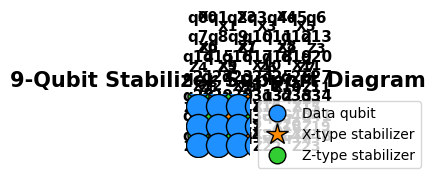

In [18]:

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Number of data qubits
n_data = 49

# X-type stabilizer supports
x_checks = [
    [0,1],[1,2,8,9],[2,3],
    [3,4,10,11],[4,5],[5,6,12,13],
    [7,8,14,15],[9,10,16,17],[11,12,18,19],
    [15,16,22,23],[17,18,24,25],[19,20,26,27],
    [21,22,28,29],[23,24,30,31],[25,26,32,33],
    [29,30,36,37],[31,32,38,39],[33,34,40,41],
    [35,36,42,43],[37,38,44,45],[39,40,46,47],
    [43,44],[45,46],[47,48]
]

# Z-type stabilizer supports
z_checks = [
    [0, 1,7,8],[2,3,9,10],[4,5,11,12],
    [6,13],[7,14],[8,9,15,16],
    [10,11,17,18],[12,13,19,20],[14,15,21,22],
    [16,17,23,24],[18,19,25,26],[20,27],
    [21,28],[22,23,29,30],[24,25,31,32],
    [26,27,33,34],[28,29,35,36],[30,31,37,38],
    [32,33,39,40],[34,41],[35,42],
    [36,37,43,44],[38,39,45,46],[40,41,47,48]
]

# --------------------------------------------------
# 1. Assign positions to the 9 data qubits
# --------------------------------------------------
# q0 q1 q2
# q3 q4 q5
# q6 q7 q8

positions = {
    0: (0, 6),
    1: (1, 6),
    2: (2, 6),
    3: (3, 6),
    4: (4, 6),
    5: (5, 6),
    6: (6, 6),
    7: (0, 5),
    8: (1, 5),
    9: (2, 5),
    10: (3, 5),
    11: (4, 5),
    12: (5, 5),
    13: (6, 5),
    14: (0, 4),
    15: (1, 4),
    16: (2, 4),
    17: (3, 4),
    18: (4, 4),
    19: (5, 4),
    20: (6, 4),
    21: (0, 3),
    22: (1, 3),
    23: (2, 3),
    24: (3, 3),
    25: (4, 3),
    26: (5, 3),
    27: (6, 3),
    28: (0, 2),
    29: (1, 2),
    30: (2, 2),
    31: (3, 2),
    32: (4, 2),
    33: (5, 2),
    34: (6, 2),
    35: (0, 1),
    36: (1, 1),
    37: (2, 1),
    38: (3, 1),
    39: (4, 1),
    40: (5, 1),
    41: (6, 1),
    42: (0, 0),
    43: (1, 0),
    44: (2, 0),
    45: (3, 0),
    46: (4, 0),
    47: (5, 0),
    48: (6, 0)

}

fig, ax = plt.subplots(figsize=(10, 8))

# --------------------------------------------------
# 2. Draw the data-qubit grid
# --------------------------------------------------
for q1 in range(n_data):
    x1, y1 = positions[q1]

    for q2 in range(q1 + 1, n_data):
        x2, y2 = positions[q2]

        # Connect nearest horizontal neighbours
        if y1 == y2 and abs(x1 - x2) == 1:
            ax.plot([x1, x2], [y1, y2],
                    color="lightgray", linewidth=1.5,
                    zorder=1)

        # Connect nearest vertical neighbours
        if x1 == x2 and abs(y1 - y2) == 1:
            ax.plot([x1, x2], [y1, y2],
                    color="lightgray", linewidth=1.5,
                    zorder=1)

# --------------------------------------------------
# 3. Draw X-type stabilizers as orange stars
# --------------------------------------------------
for i, support in enumerate(x_checks):
    xs = [positions[q][0] for q in support]
    ys = [positions[q][1] for q in support]

    # Stabilizer symbol at the centre of its support
    sx = sum(xs) / len(xs)
    sy = sum(ys) / len(ys)

    # Connect the stabilizer to its data qubits
    for q in support:
        x, y = positions[q]
        ax.plot([sx, x], [sy, y],
                color="darkorange", alpha=0.7,
                linewidth=1.5, zorder=2)

    ax.scatter(sx, sy, marker="*",
               s=500, color="darkorange",
               edgecolor="black", zorder=4)

    ax.text(sx, sy + 0.20, f"X{i}",
            ha="center", va="bottom",
            fontsize=10, fontweight="bold")

# --------------------------------------------------
# 4. Draw Z-type stabilizers as green dots
# --------------------------------------------------
for i, support in enumerate(z_checks):
    xs = [positions[q][0] for q in support]
    ys = [positions[q][1] for q in support]

    sx = sum(xs) / len(xs)
    sy = sum(ys) / len(ys)

    # Connect the stabilizer to its data qubits
    for q in support:
        x, y = positions[q]
        ax.plot([sx, x], [sy, y],
                color="seagreen", alpha=0.7,
                linewidth=1.5, zorder=2)

    ax.scatter(sx, sy, marker="o",
               s=230, color="limegreen",
               edgecolor="black", zorder=4)

    ax.text(sx, sy - 0.20, f"Z{i}",
            ha="center", va="top",
            fontsize=10, fontweight="bold")

# --------------------------------------------------
# 5. Draw data qubits on top of the connections
# --------------------------------------------------
for q in range(n_data):
    x, y = positions[q]

    ax.scatter(x, y, s=300, color="dodgerblue",
               edgecolor="black", zorder=5)

    ax.text(x, y + 0.12, f"q{q}",
            ha="center", va="bottom",
            fontsize=11, fontweight="bold")

# --------------------------------------------------
# 6. Add legend, title and formatting
# --------------------------------------------------
legend_items = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="dodgerblue",
           markeredgecolor="black", markersize=12,
           label="Data qubit"),
    Line2D([0], [0], marker="*", color="w",
           markerfacecolor="darkorange",
           markeredgecolor="black", markersize=16,
           label="X-type stabilizer"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="limegreen",
           markeredgecolor="black", markersize=12,
           label="Z-type stabilizer")
]

ax.legend(handles=legend_items, loc="upper left",
          bbox_to_anchor=(1.02, 1))

ax.set_title("9-Qubit Stabilizer Support Diagram",
             fontsize=15, fontweight="bold")

ax.set_aspect("equal")
ax.set_xlim(-0.6, 2.6)
ax.set_ylim(-0.6, 2.6)
ax.axis("off")

plt.tight_layout()
plt.savefig("surface_code_support.png",
            dpi=300, bbox_inches="tight")
plt.show()


Number of data qubits: 49
Number of X checks: 24
Number of Z checks: 24


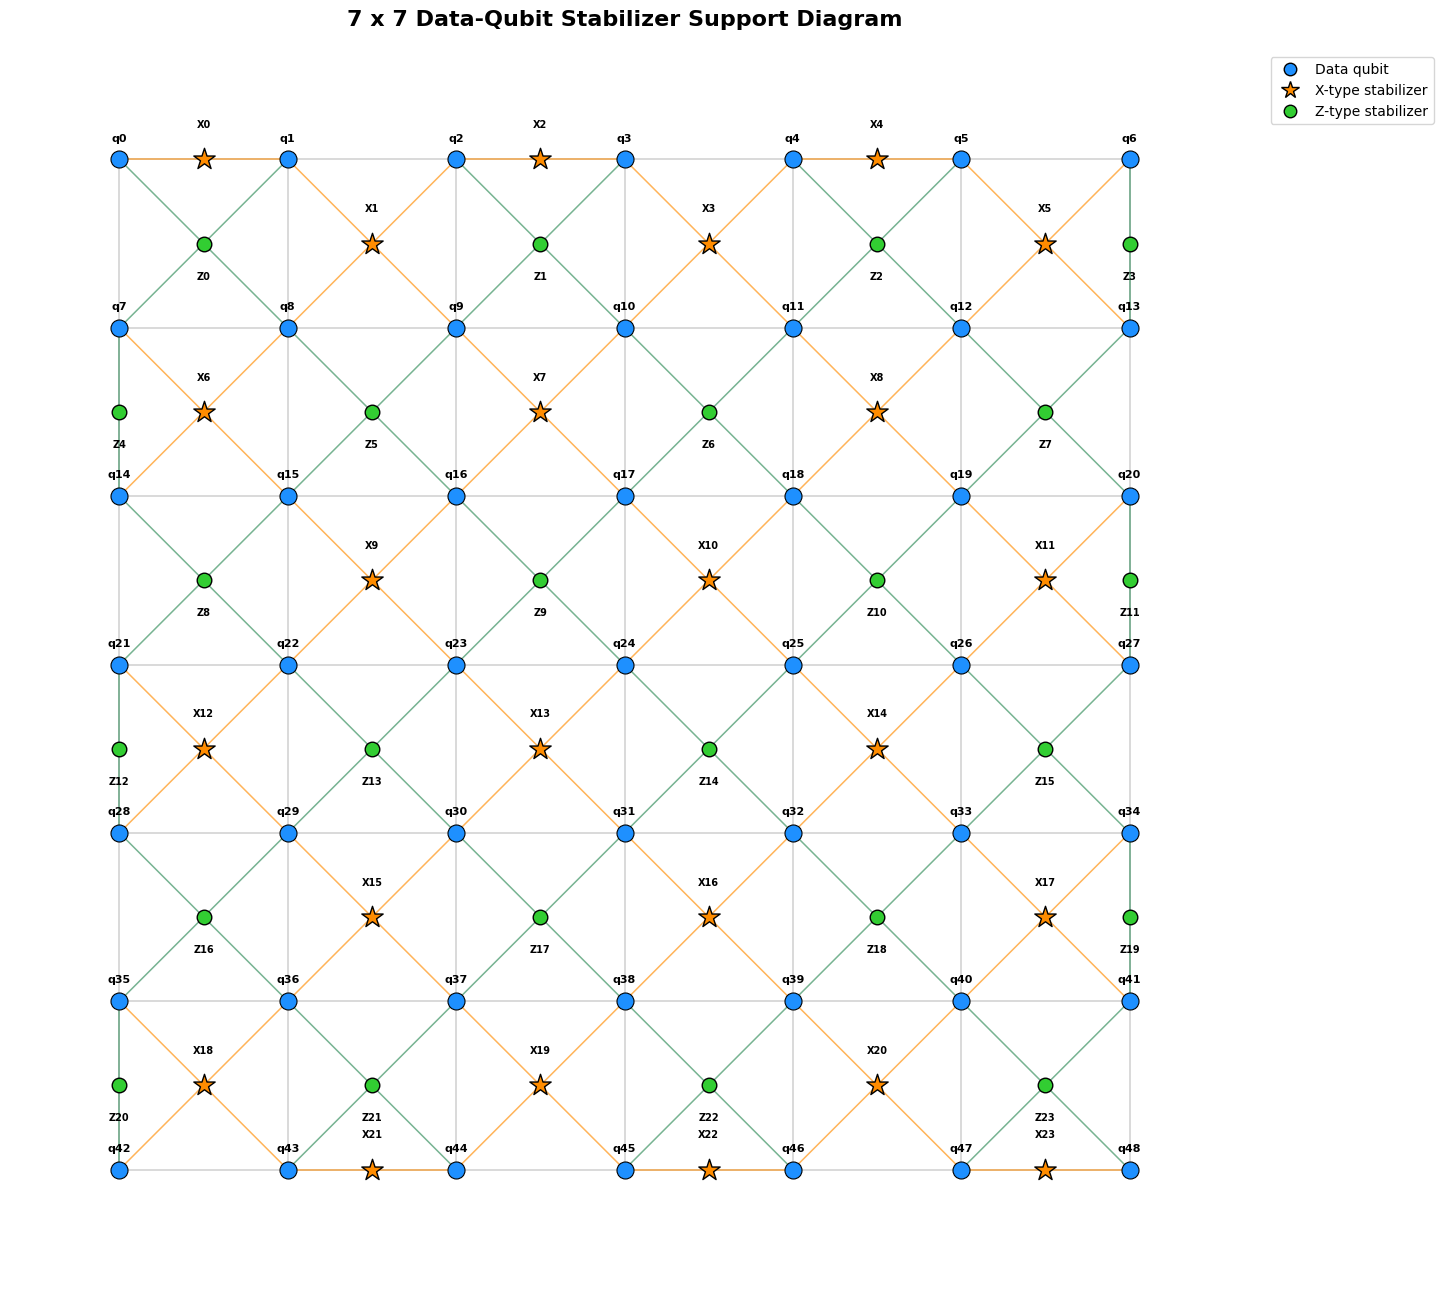

In [19]:

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==================================================
# 1. Define the 49 data qubits and stabilizer supports
# ==================================================

n_data = 49
grid_size = 7

# X-type stabilizer supports (unchanged)
x_checks = [
    [0, 1], [1, 2, 8, 9], [2, 3],
    [3, 4, 10, 11], [4, 5], [5, 6, 12, 13],
    [7, 8, 14, 15], [9, 10, 16, 17], [11, 12, 18, 19],
    [15, 16, 22, 23], [17, 18, 24, 25], [19, 20, 26, 27],
    [21, 22, 28, 29], [23, 24, 30, 31], [25, 26, 32, 33],
    [29, 30, 36, 37], [31, 32, 38, 39], [33, 34, 40, 41],
    [35, 36, 42, 43], [37, 38, 44, 45], [39, 40, 46, 47],
    [43, 44], [45, 46], [47, 48]
]

# Z-type stabilizer supports (unchanged)
z_checks = [
    [0, 1, 7, 8], [2, 3, 9, 10], [4, 5, 11, 12],
    [6, 13], [7, 14], [8, 9, 15, 16],
    [10, 11, 17, 18], [12, 13, 19, 20], [14, 15, 21, 22],
    [16, 17, 23, 24], [18, 19, 25, 26], [20, 27],
    [21, 28], [22, 23, 29, 30], [24, 25, 31, 32],
    [26, 27, 33, 34], [28, 29, 35, 36], [30, 31, 37, 38],
    [32, 33, 39, 40], [34, 41], [35, 42],
    [36, 37, 43, 44], [38, 39, 45, 46], [40, 41, 47, 48]
]

print("Number of data qubits:", n_data)
print("Number of X checks:", len(x_checks))
print("Number of Z checks:", len(z_checks))

# ==================================================
# 2. Automatically assign positions to a 7 x 7 grid
# ==================================================
# q0  q1  q2  q3  q4  q5  q6
# q7  q8  q9  q10 q11 q12 q13
# ...
# q42 q43 q44 q45 q46 q47 q48

positions = {
    q: (q % grid_size, grid_size - 1 - q // grid_size)
    for q in range(n_data)
}

# Check that all support indices are valid
for support in x_checks + z_checks:
    assert all(0 <= q < n_data for q in support), \
        "A stabilizer refers to an invalid data-qubit index."

# ==================================================
# 3. Create the figure
# ==================================================

fig, ax = plt.subplots(figsize=(15, 13))

# ==================================================
# 4. Draw connections between neighbouring data qubits
# ==================================================

for q in range(n_data):
    x, y = positions[q]

    # Connect to the right-hand neighbour
    if q % grid_size != grid_size - 1:
        x2, y2 = positions[q + 1]
        ax.plot([x, x2], [y, y2],
                color="lightgray", linewidth=1.2, zorder=1)

    # Connect to the neighbour in the next row
    if q + grid_size < n_data:
        x2, y2 = positions[q + grid_size]
        ax.plot([x, x2], [y, y2],
                color="lightgray", linewidth=1.2, zorder=1)

# ==================================================
# 5. Draw X-type stabilizers as orange stars
# ==================================================

for i, support in enumerate(x_checks):
    xs = [positions[q][0] for q in support]
    ys = [positions[q][1] for q in support]

    # Centre of the stabilizer's supporting qubits
    sx = sum(xs) / len(xs)
    sy = sum(ys) / len(ys)

    # Draw lines from the star to its supporting qubits
    for q in support:
        x, y = positions[q]
        ax.plot([sx, x], [sy, y],
                color="darkorange", alpha=0.65,
                linewidth=1.1, zorder=2)

    ax.scatter(sx, sy, marker="*",
               s=260, color="darkorange",
               edgecolor="black", zorder=4)

    ax.text(sx, sy + 0.18, f"X{i}",
            ha="center", va="bottom",
            fontsize=7, fontweight="bold", zorder=6)

# ==================================================
# 6. Draw Z-type stabilizers as green dots
# ==================================================

for i, support in enumerate(z_checks):
    xs = [positions[q][0] for q in support]
    ys = [positions[q][1] for q in support]

    sx = sum(xs) / len(xs)
    sy = sum(ys) / len(ys)

    # Draw lines from the dot to its supporting qubits
    for q in support:
        x, y = positions[q]
        ax.plot([sx, x], [sy, y],
                color="seagreen", alpha=0.65,
                linewidth=1.1, zorder=2)

    ax.scatter(sx, sy, marker="o",
               s=110, color="limegreen",
               edgecolor="black", zorder=4)

    ax.text(sx, sy - 0.16, f"Z{i}",
            ha="center", va="top",
            fontsize=7, fontweight="bold", zorder=6)

# ==================================================
# 7. Draw data qubits on top
# ==================================================

for q in range(n_data):
    x, y = positions[q]

    ax.scatter(x, y, s=150, color="dodgerblue",
               edgecolor="black", linewidth=0.8, zorder=5)

    ax.text(x, y + 0.10, f"q{q}",
            ha="center", va="bottom",
            fontsize=8, fontweight="bold", zorder=7)

# ==================================================
# 8. Legend
# ==================================================

legend_items = [
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="dodgerblue",
           markeredgecolor="black", markersize=9,
           label="Data qubit"),
    Line2D([0], [0], marker="*", color="w",
           markerfacecolor="darkorange",
           markeredgecolor="black", markersize=13,
           label="X-type stabilizer"),
    Line2D([0], [0], marker="o", color="w",
           markerfacecolor="limegreen",
           markeredgecolor="black", markersize=9,
           label="Z-type stabilizer")
]

ax.legend(handles=legend_items, loc="upper left",
          bbox_to_anchor=(1.02, 1), fontsize=10)

# ==================================================
# 9. Format and save the diagram
# ==================================================

ax.set_title(
    "7 x 7 Data-Qubit Stabilizer Support Diagram",
    fontsize=16, fontweight="bold", pad=18
)

ax.set_aspect("equal")
ax.set_xlim(-0.65, 6.65)
ax.set_ylim(-0.65, 6.65)
ax.axis("off")

plt.tight_layout()

plt.savefig(
    "surface_code_7x7_support.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [28]:

# =====================================================
# STEP 1: Calculate the syndrome for a single error
# =====================================================

def calculate_syndrome(error_type, qubit):
    """
    Return the X-check and Z-check syndrome bits.

    X error -> flips Z checks containing the qubit
    Z error -> flips X checks containing the qubit
    Y error -> flips both types
    """

    error_type = error_type.upper()

    if error_type not in ("X", "Y", "Z"):
        raise ValueError("error_type must be X, Y, or Z")

    if not 0 <= qubit < n_data:
        raise ValueError("Invalid data-qubit index")

    # Z checks detect X components of errors
    z_syndrome = [
        int(qubit in support)
        if error_type in ("X", "Y") else 0
        for support in z_checks
    ]

    # X checks detect Z components of errors
    x_syndrome = [
        int(qubit in support)
        if error_type in ("Z", "Y") else 0
        for support in x_checks
    ]

    # Combine both parts into one syndrome signature
    return tuple(x_syndrome + z_syndrome)


# =====================================================
# STEP 2: Build a lookup table for all single-qubit errors
# =====================================================

error_lookup = {}

for q in range(n_data):
    for error_type in ("X", "Y", "Z"):
        syndrome = calculate_syndrome(error_type, q)

        # Keep all candidates in case a syndrome is ambiguous
        error_lookup.setdefault(syndrome, []).append(
            (error_type, q)
        )


# =====================================================
# STEP 3: Inject one error
# =====================================================

# error_type = "X"
# error_qubit = 17

# measured_syndrome = calculate_syndrome(
#     error_type, error_qubit
# )

# print(f"Injected error: {error_type} on q{error_qubit}")

# print("X-check syndrome:",
#       measured_syndrome[:len(x_checks)])

# print("Z-check syndrome:",
#       measured_syndrome[len(x_checks):])



# Multiple errors: (error type, data-qubit number)
errors = [
    ("X", 17),
    ("Z", 18),
    ("Y", 19)
]

def calculate_multiple_syndrome(errors):
    # Start with all syndrome bits equal to zero
    total_syndrome = [0] * (len(x_checks) + len(z_checks))

    for error_type, qubit in errors:
        # Calculate the syndrome caused by this individual error
        single_syndrome = calculate_syndrome(error_type, qubit)

        # Combine syndromes using XOR (addition modulo 2)
        total_syndrome = [
            old_bit ^ new_bit
            for old_bit, new_bit in zip(
                total_syndrome, single_syndrome
            )
        ]

    return total_syndrome


syndrome = calculate_multiple_syndrome(errors)

print("Injected errors:")
for error_type, qubit in errors:
    print(f"{error_type} error on qubit {qubit}")

print("\nCombined syndrome:")
print(syndrome)

print("\nX-check syndrome:", syndrome[:len(x_checks)])
print("Z-check syndrome:", syndrome[len(x_checks):])




# =====================================================
# STEP 4: Search for error patterns up to weight 3
# =====================================================

from itertools import combinations, product

target_syndrome = tuple(syndrome)
pauli_types = ("X", "Y", "Z")
max_errors = 3

solutions = []

for weight in range(1, max_errors + 1):
    for qubits in combinations(range(n_data), weight):
        for types in product(pauli_types, repeat=weight):

            candidate_errors = list(zip(types, qubits))

            candidate_syndrome = tuple(
                calculate_multiple_syndrome(candidate_errors)
            )

            if candidate_syndrome == target_syndrome:
                solutions.append(candidate_errors)

    # Stop at the first weight with matching patterns
    if solutions:
        print(f"\nMatching patterns with weight {weight}:")
        for candidate in solutions:
            print(candidate)
        break

if not solutions:
    print(f"No matching pattern found up to weight {max_errors}.")



Injected errors:
X error on qubit 17
Z error on qubit 18
Y error on qubit 19

Combined syndrome:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

X-check syndrome: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Z-check syndrome: [0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Matching patterns with weight 3:
[('X', 17), ('Z', 18), ('Y', 19)]


In [29]:

# =====================================================
# STEP 2: MATHEMATICAL VALIDATION OF THE STABILIZERS
# =====================================================

# 1. Validate that all supports contain valid qubit indices
all_checks = x_checks + z_checks

for i, support in enumerate(all_checks):
    assert len(support) == len(set(support)), (
        f"Duplicate qubit in stabilizer {i}"
    )
    assert all(0 <= q < n_data for q in support), (
        f"Invalid qubit index in stabilizer {i}"
    )

print("PASS: All stabilizer supports have valid qubit indices.")


# 2. Check commutation between every X-check and Z-check
anticommuting_pairs = []

for i, x_support in enumerate(x_checks):
    for j, z_support in enumerate(z_checks):
        overlap = set(x_support) & set(z_support)

        if len(overlap) % 2 != 0:
            anticommuting_pairs.append(
                (i, j, sorted(overlap))
            )

if anticommuting_pairs:
    print("\nFAIL: Some X and Z checks anticommute.")
    for x_id, z_id, overlap in anticommuting_pairs:
        print(
            f"X{x_id} and Z{z_id}: "
            f"overlap = {overlap}"
        )
else:
    print("PASS: Every X-check commutes with every Z-check.")


# 3. Calculate matrix rank over GF(2)
# GF(2) means arithmetic modulo 2.

def binary_rank(checks, n_qubits):
    rows = []

    for support in checks:
        row = [0] * n_qubits
        for q in support:
            row[q] = 1
        rows.append(row)

    pivot_row = 0

    for col in range(n_qubits):
        pivot = next(
            (
                r for r in range(pivot_row, len(rows))
                if rows[r][col] == 1
            ),
            None
        )

        if pivot is None:
            continue

        rows[pivot_row], rows[pivot] = (
            rows[pivot], rows[pivot_row]
        )

        for r in range(len(rows)):
            if r != pivot_row and rows[r][col] == 1:
                rows[r] = [
                    a ^ b
                    for a, b in zip(
                        rows[r], rows[pivot_row]
                    )
                ]

        pivot_row += 1

        if pivot_row == len(rows):
            break

    return pivot_row


rank_x = binary_rank(x_checks, n_data)
rank_z = binary_rank(z_checks, n_data)

# Only interpret k if the stabilizers commute.
if not anticommuting_pairs:
    k = n_data - rank_x - rank_z

    print("\n--- Stabilizer rank results ---")
    print("Number of data qubits:", n_data)
    print("Number of X checks:", len(x_checks))
    print("Independent X checks:", rank_x)
    print("Number of Z checks:", len(z_checks))
    print("Independent Z checks:", rank_z)
    print("Total independent checks:", rank_x + rank_z)
    print("Encoded logical qubits k =", k)

    if k < 0:
        print("FAIL: Check the stabilizer definitions.")
    elif k == 1:
        print("The stabilizer ranks are consistent with 1 logical qubit.")
    else:
        print(f"The stabilizer ranks imply {k} logical qubits.")
else:
    print("\nDo not infer the encoded qubit count yet.")
    print("Fix the anticommuting stabilizers first.")


PASS: All stabilizer supports have valid qubit indices.
PASS: Every X-check commutes with every Z-check.

--- Stabilizer rank results ---
Number of data qubits: 49
Number of X checks: 24
Independent X checks: 24
Number of Z checks: 24
Independent Z checks: 24
Total independent checks: 48
Encoded logical qubits k = 1
The stabilizer ranks are consistent with 1 logical qubit.


In [30]:

import numpy as np

# Convert a list of stabilizer supports into a binary matrix
def make_matrix(checks, n):
    H = np.zeros((len(checks), n), dtype=np.uint8)
    for i, support in enumerate(checks):
        H[i, support] = 1
    return H


# Gaussian elimination over GF(2)
def rref_gf2(A):
    A = np.array(A, dtype=np.uint8).copy()
    rows, cols = A.shape
    pivot_cols = []
    r = 0

    for c in range(cols):
        pivots = np.where(A[r:, c] == 1)[0]
        if len(pivots) == 0:
            continue

        p = r + pivots[0]
        A[[r, p]] = A[[p, r]]

        for i in range(rows):
            if i != r and A[i, c]:
                A[i] ^= A[r]

        pivot_cols.append(c)
        r += 1

        if r == rows:
            break

    return A, pivot_cols


# Find a basis for the nullspace of A over GF(2)
def nullspace_gf2(A):
    R, pivots = rref_gf2(A)
    n = A.shape[1]
    free_cols = [c for c in range(n) if c not in pivots]
    basis = []

    for free in free_cols:
        v = np.zeros(n, dtype=np.uint8)
        v[free] = 1

        for row, pivot in enumerate(pivots):
            v[pivot] = R[row, free]

        basis.append(v)

    return basis


# Check if v belongs to the row space of A
def in_rowspace(A, v):
    before = len(A)
    after = len(rref_gf2(np.vstack([A, v]))[1])
    return before == after


Hx = make_matrix(x_checks, n_data)
Hz = make_matrix(z_checks, n_data)

# An X-type logical operator must commute with all Z checks.
x_candidates = nullspace_gf2(Hz)

logical_x = next(
    (v for v in x_candidates if not in_rowspace(Hx, v)),
    None
)

# A Z-type logical operator must commute with all X checks.
z_candidates = nullspace_gf2(Hx)

logical_z = None

if logical_x is not None:
    for v in z_candidates:
        if not in_rowspace(Hz, v):
            # X_L and Z_L must anticommute:
            # their supports must overlap oddly.
            if int(np.dot(logical_x, v) % 2) == 1:
                logical_z = v
                break


# Display results
if logical_x is None:
    print("No nontrivial X logical operator found.")
elif logical_z is None:
    print("Found X_L, but did not find a paired Z_L.")
else:
    x_support = np.flatnonzero(logical_x).tolist()
    z_support = np.flatnonzero(logical_z).tolist()

    print("Logical X_L support:", x_support)
    print("Logical Z_L support:", z_support)
    print("Weight of X_L:", len(x_support))
    print("Weight of Z_L:", len(z_support))
    print(
        "Overlap:",
        len(set(x_support) & set(z_support))
    )
    print("Logical operators anticommute: YES")


Logical X_L support: [0, 7, 14, 21, 28, 35, 42]
Logical Z_L support: [0, 1, 2, 3, 4, 5, 6]
Weight of X_L: 7
Weight of Z_L: 7
Overlap: 1
Logical operators anticommute: YES


In [31]:

from itertools import combinations

def find_minimum_logical_weight(check_matrix, stabilizer_matrix,
                                n_qubits, max_weight=7):
    """
    Find the smallest nontrivial logical operator of one Pauli type.
    Returns its weight and one support, or None if not found
    within max_weight.
    """
    for weight in range(1, max_weight + 1):
        for support in combinations(range(n_qubits), weight):
            v = np.zeros(n_qubits, dtype=np.uint8)
            v[list(support)] = 1

            # Commutes with all checks of the opposite Pauli type
            if np.any((check_matrix @ v) % 2):
                continue

            # Must not be a product of same-type stabilizers
            if in_rowspace(stabilizer_matrix, v):
                continue

            return weight, list(support)

    return None


# X logicals commute with Z checks and must not be X stabilizers.
min_x = find_minimum_logical_weight(
    Hz, Hx, n_data, max_weight=7
)

# Z logicals commute with X checks and must not be Z stabilizers.
min_z = find_minimum_logical_weight(
    Hx, Hz, n_data, max_weight=7
)

print("Minimum X-logical found:", min_x)
print("Minimum Z-logical found:", min_z)

if min_x is not None and min_z is not None:
    print("CSS code distance:", min(min_x[0], min_z[0]))
else:
    print("At least one minimum was not found within weight 7.")


Minimum X-logical found: (7, [0, 7, 14, 21, 28, 35, 42])
Minimum Z-logical found: (7, [0, 1, 2, 3, 4, 5, 6])
CSS code distance: 7
